
Step1 : loading dataset...
dataset shape: (13000, 25)

missing values:
offer_type    6544
dtype: int64

Step2 : starting feature engg...
feature engineering complete. final shape: (13000, 48)

Step3 : building demand forecasting model...

demand forecast performance:
  mae: 35.51 units
  rmse: 46.20 units
  r2 score: 0.8809

top 10 demand drivers:
              feature  importance
         demand_index    0.879165
               rating    0.023041
    profit_margin_pct    0.009657
          num_reviews    0.009207
     days_since_added    0.009028
    days_until_expiry    0.006986
stock_to_demand_ratio    0.006921
      shelf_life_days    0.006722
          final_price    0.006222
                price    0.006109

Step4 : inventory optimization engine...

inventory insights:
  products at stockout risk: 4010
  products at wastage risk: 3885
  total predicted wastage: 127975 units
  average inventory health score: 68.7/100

inventory actions required:
inventory_action
Increase Stock  

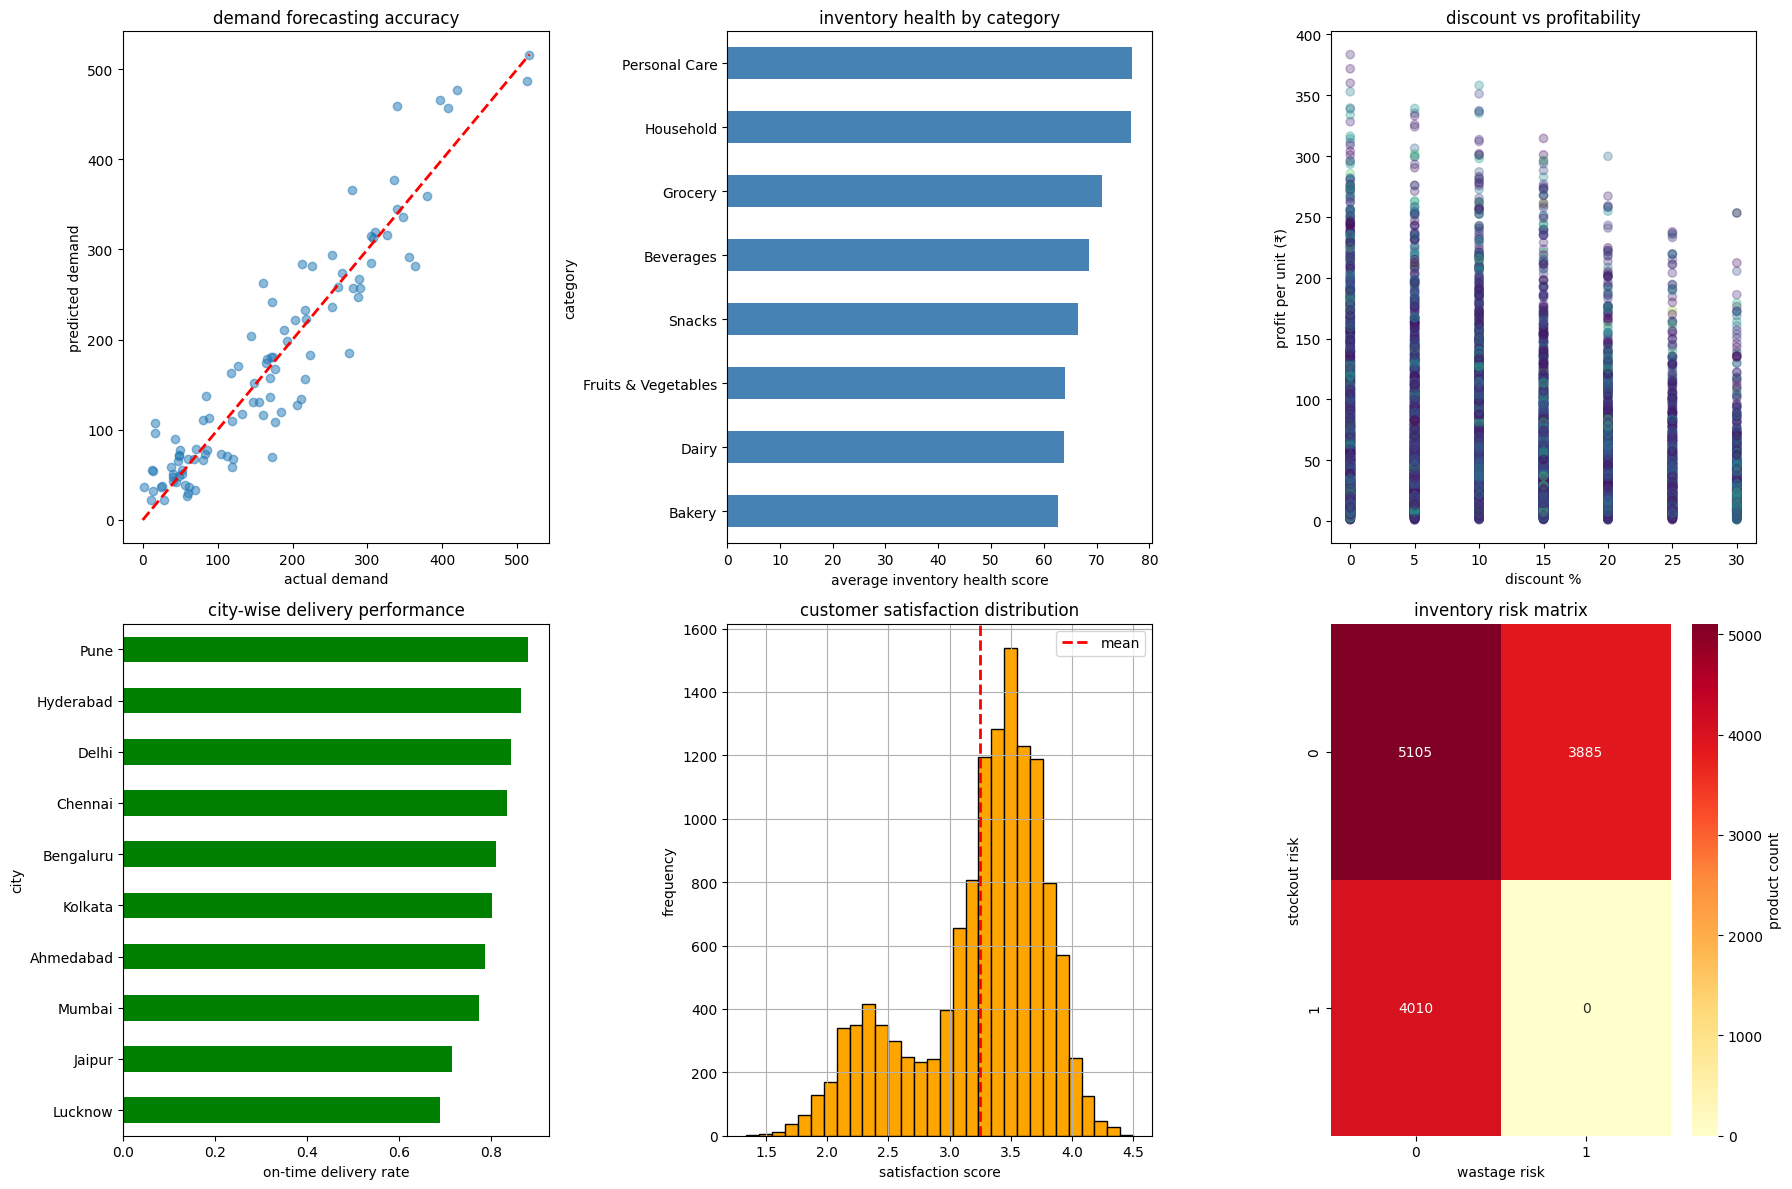


processed dataset saved: blinkit_processed_dataset.csv
total columns: 76


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans


def load_and_preprocess_data(filepath='/kaggle/input/blinkit-dataset/blinkit_dataset.csv'):

    print("\nStep1 : loading dataset...")
    
    df = pd.read_csv(filepath)
    print(f"dataset shape: {df.shape}")
    
    # parse dates
    df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', dayfirst=False, errors='coerce')
    df['expiry_date'] = pd.to_datetime(df['expiry_date'], format='mixed', dayfirst=False, errors='coerce')
    
    # convert boolean
    df['is_organic'] = df['is_organic'].map({'TRUE': 1, 'False': 0, 'FALSE': 0, True: 1, False: 0})
    
    missing = df.isnull().sum()[df.isnull().sum() > 0]
    if len(missing) > 0:
        print(f"\nmissing values:\n{missing}")
    
    return df


def engineer_features(df):   # feature engg - derived cols only

    print("\nStep2 : starting feature engg...")
    
    df = df.copy()
    
    # time based features
    df['days_since_added'] = (pd.Timestamp.now() - df['date_added']).dt.days
    df['days_until_expiry'] = (df['expiry_date'] - pd.Timestamp.now()).dt.days
    df['remaining_shelf_life_pct'] = (df['days_until_expiry'] / df['shelf_life_days']) * 100
    df['remaining_shelf_life_pct'] = df['remaining_shelf_life_pct'].clip(0, 100)
    
    # inventory efficiency metrics
    df['stock_to_demand_ratio'] = df['stock'] / (df['demand_index'] + 1)
    df['stockout_risk'] = ((df['stock'] <= df['reorder_level']) | 
                           (df['stock'] < df['sold_quantity'] * 0.5)).astype(int)
    df['wastage_risk'] = ((df['days_until_expiry'] < 7) & (df['stock'] > df['sold_quantity'])).astype(int)
    df['inventory_turnover'] = df['sold_quantity'] / (df['stock'] + 1)
    df['days_of_inventory'] = df['stock'] / (df['sold_quantity'] / 30 + 1)
    
    # pricing and profitability metrics
    df['discount_amount'] = df['price'] - df['final_price']
    df['revenue_per_unit'] = df['final_price']
    df['profit_per_unit'] = df['final_price'] * (df['profit_margin_pct'] / 100)
    df['total_revenue'] = df['sold_quantity'] * df['final_price']
    df['total_profit'] = df['sold_quantity'] * df['profit_per_unit']
    df['price_per_gram'] = df['final_price'] / (df['weight_g'] + 1)
    
    # customer behavior metrics
    df['engagement_score'] = df['num_reviews'] * df['rating']
    df['rating_category'] = pd.cut(df['rating'], bins=[0, 3.5, 4.0, 5.0], labels=['Low', 'Medium', 'High'])
    df['high_rated'] = (df['rating'] >= 4.0).astype(int)
    df['delivery_performance'] = (df['delivery_status'] == 'On-Time').astype(int)
    
    # category and segmentation
    df['is_perishable'] = (df['shelf_life_days'] < 30).astype(int)
    df['is_fast_moving'] = (df['demand_index'] > df['demand_index'].median()).astype(int)
    df['premium_product'] = (df['final_price'] > df.groupby('category')['final_price'].transform('median')).astype(int)
    
    # offer effectiveness
    df['has_offer'] = (df['offer_type'] != 'None').astype(int)
    df['discount_effectiveness'] = df['sold_quantity'] / (df['discount_pct'] + 1)
    
    print(f"feature engineering complete. final shape: {df.shape}")
    
    return df


# demand forecasting model
def build_demand_forecast_model(df):   #to predict sold quantity based on multiple factors

    print("\nStep3 : building demand forecasting model...")
    
    # preP features
    feature_cols = ['price', 'discount_pct', 'final_price', 'rating', 'num_reviews',
                    'stock', 'profit_margin_pct', 'is_organic', 'weight_g', 'shelf_life_days',
                    'reorder_level', 'demand_index', 'days_since_added', 'days_until_expiry',
                    'remaining_shelf_life_pct', 'stock_to_demand_ratio', 'is_perishable',
                    'is_fast_moving', 'has_offer', 'delivery_performance']
    
    # encode categorical var
    le_city = LabelEncoder()
    le_category = LabelEncoder()
    le_brand = LabelEncoder()
    le_packaging = LabelEncoder()
    
    df['city_encoded'] = le_city.fit_transform(df['city'])
    df['category_encoded'] = le_category.fit_transform(df['category'])
    df['brand_encoded'] = le_brand.fit_transform(df['brand'])
    df['packaging_encoded'] = le_packaging.fit_transform(df['packaging_type'])
    
    feature_cols += ['city_encoded', 'category_encoded', 'brand_encoded', 'packaging_encoded']
    
    # prep training data
    X = df[feature_cols].fillna(0)
    y = df['sold_quantity']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # train random forest model
    model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    
    # evaluate model
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    print(f"\ndemand forecast performance:")
    print(f"  mae: {mae:.2f} units")
    print(f"  rmse: {rmse:.2f} units")
    print(f"  r2 score: {r2:.4f}")
    
    # feature imp analysis
    feature_imp = pd.DataFrame({
        'feature': feature_cols,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False).head(10)
    
    print(f"\ntop 10 demand drivers:")
    print(feature_imp.to_string(index=False))
    
    # add predictions to dataframe
    df['predicted_demand'] = model.predict(X)
    df['demand_forecast_error'] = abs(df['sold_quantity'] - df['predicted_demand'])
    
    return model, df, (le_city, le_category, le_brand, le_packaging)

    
# inventory optimization engine
def optimize_inventory(df):   #to calc optimal reorder quantities and stockout/wastage predictions

    print("\nStep4 : inventory optimization engine...")
    
    # calc optimal stock levels
    df['optimal_stock'] = (df['predicted_demand'] * 1.2).round()
    df['stock_adjustment_needed'] = df['optimal_stock'] - df['stock']
    df['reorder_urgency'] = df['stockout_risk'] * df['demand_index']
    
    # wastage prediction for perishables near expiry
    df['predicted_wastage'] = 0
    wastage_condition = (df['is_perishable'] == 1) & (df['days_until_expiry'] < 10)
    df.loc[wastage_condition, 'predicted_wastage'] = (
        df.loc[wastage_condition, 'stock'] - df.loc[wastage_condition, 'predicted_demand']
    ).clip(lower=0)
    
    # inventory health score calc
    turnover_score = np.minimum(df['inventory_turnover'] * 20, 35)
    stock_bal_score = np.where(
        df['stock_to_demand_ratio'].between(0.8, 1.5), 35,
        np.where(df['stock_to_demand_ratio'] < 0.8, 35 - (0.8 - df['stock_to_demand_ratio']) * 50, 
                 35 - (df['stock_to_demand_ratio'] - 1.5) * 20)
    ).clip(0, 35)
    
    df['inventory_health_score'] = (
        (1 - df['stockout_risk']) * 30 +
        (1 - df['wastage_risk']) * 30 +
        turnover_score +
        stock_bal_score.clip(0, 10)
    ).round(1)
    
    # gen actionable recommendations
    df['inventory_action'] = 'Maintain'
    df.loc[df['stockout_risk'] == 1, 'inventory_action'] = 'Urgent Reorder'
    df.loc[df['wastage_risk'] == 1, 'inventory_action'] = 'Discount to Clear'
    df.loc[df['stock_adjustment_needed'] > 50, 'inventory_action'] = 'Increase Stock'
    
    print("\ninventory insights:")
    print(f"  products at stockout risk: {df['stockout_risk'].sum()}")
    print(f"  products at wastage risk: {df['wastage_risk'].sum()}")
    print(f"  total predicted wastage: {df['predicted_wastage'].sum():.0f} units")
    print(f"  average inventory health score: {df['inventory_health_score'].mean():.1f}/100")
    print(f"\ninventory actions required:")
    print(df['inventory_action'].value_counts())
    
    return df

    
# discount optimization model
def optimize_discounts(df):   #to find optimal discount levels that maximize profit while maintaining satisfaction

    print("\nStep5 : discount optimization model...")
    
    # analyze discount performance
    df['profit_per_discount'] = df['total_profit'] / (df['discount_pct'] + 1)
    df['margin_erosion'] = df['discount_pct'] * df['profit_margin_pct'] / 100
    
    # calc discount efficiency
    df['discount_efficiency'] = (
        (df['sold_quantity'] / (df['discount_pct'] + 1)) * 
        (df['profit_margin_pct'] / 100)
    )
    
    # optimal discount recommendation logic
    df['recommended_discount'] = 0
    
    # high performers get minimal discount
    high_performers = (df['high_rated'] == 1) & (df['is_fast_moving'] == 1)
    df.loc[high_performers, 'recommended_discount'] = np.minimum(df.loc[high_performers, 'discount_pct'], 10)
    
    # wastage items get aggressive discount
    wastage_items = df['wastage_risk'] == 1
    df.loc[wastage_items, 'recommended_discount'] = 30
    
    # slow movers get moderate discount
    slow_movers = (df['is_fast_moving'] == 0) & (df['wastage_risk'] == 0)
    df.loc[slow_movers, 'recommended_discount'] = 15
    
    # stockout items should have no discount
    stockout_items = df['stockout_risk'] == 1
    df.loc[stockout_items, 'recommended_discount'] = 0
    
    df['discount_change'] = df['recommended_discount'] - df['discount_pct']
    
    # project impact of recommendations
    df['projected_new_price'] = df['price'] * (1 - df['recommended_discount'] / 100)
    df['projected_profit_margin'] = df['profit_margin_pct'] - (df['recommended_discount'] * 0.3)
    df['projected_revenue_impact'] = (df['projected_new_price'] - df['final_price']) * df['predicted_demand']
    
    print("\ndiscount optimization results:")
    print(f"  current avg discount: {df['discount_pct'].mean():.1f}%")
    print(f"  recommended avg discount: {df['recommended_discount'].mean():.1f}%")
    print(f"  products needing discount increase: {(df['discount_change'] > 0).sum()}")
    print(f"  products needing discount decrease: {(df['discount_change'] < 0).sum()}")
    print(f"  projected total revenue impact: ₹{df['projected_revenue_impact'].sum():,.0f}")
    
    return df

    
def predict_delivery_performance(df):   #to predict delivery delays and optimize routing
    
    print("\nStep6 : delivery performance prediction...")
    
    # prep features for delivery prediction
    delivery_features = ['weight_g', 'stock', 'sold_quantity', 'demand_index',
                        'is_perishable', 'city_encoded', 'category_encoded']
    
    X = df[delivery_features].fillna(0)
    y = df['delivery_performance']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # train gradient boosting classifier
    model = GradientBoostingClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    # evaluate model
    y_pred = model.predict(X_test)
    accuracy = (y_pred == y_test).mean()
    
    print(f"\ndelivery performance model accuracy: {accuracy:.2%}")
    
    # add predictions to df
    df['delivery_delay_risk'] = 1 - model.predict_proba(X)[:, 1]
    df['priority_delivery'] = (
        (df['delivery_delay_risk'] > 0.3) & 
        (df['is_perishable'] == 1) & 
        (df['high_rated'] == 1)
    ).astype(int)
    
    print(f"\ndelivery insights:")
    print(f"  current on-time delivery rate: {df['delivery_performance'].mean():.2%}")
    print(f"  high-risk deliveries: {(df['delivery_delay_risk'] > 0.5).sum()}")
    print(f"  priority deliveries required: {df['priority_delivery'].sum()}")
    
    # city-wise performance analysis
    city_performance = df.groupby('city').agg({
        'delivery_performance': 'mean',
        'delivery_time_min': 'mean',
        'delivery_delay_risk': 'mean'
    }).round(3)
    
    print(f"\ncity-wise delivery performance:")
    print(city_performance)
    
    print(f"\ndelivery optimization opportunities:")
    print(f"  cities needing improvement (< 75% on-time): {(city_performance['delivery_performance'] < 0.75).sum()}")
    print(f"  fastest city: {city_performance['delivery_time_min'].idxmin()} ({city_performance['delivery_time_min'].min():.1f} min)")
    print(f"  slowest city: {city_performance['delivery_time_min'].idxmax()} ({city_performance['delivery_time_min'].max():.1f} min)")
    
    return model, df, city_performance

    
# customer satisfaction model
def analyze_customer_satisfaction(df):   #analyze factors driving customer satisfaction and predict ratings"""
   
    print("\nStep7 : customer satisfaction analysis...")
    
    # customer segmentation using clustering
    cluster_features = ['rating', 'num_reviews', 'delivery_time_min', 
                       'final_price', 'engagement_score']
    
    X_cluster = df[cluster_features].fillna(df[cluster_features].mean())
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_cluster)
    
    # apply k-means clustering
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    df['customer_segment'] = kmeans.fit_predict(X_scaled)
    
    # analyze segments and assign labels
    segment_profiles = df.groupby('customer_segment').agg({
        'rating': 'mean',
        'final_price': 'mean',
        'num_reviews': 'mean',
        'delivery_performance': 'mean'
    })
    
    # assign meaningful labels based on characteristics
    segment_labels = {}
    for seg in segment_profiles.index:
        profile = segment_profiles.loc[seg]
        if profile['rating'] >= 4.3 and profile['final_price'] > segment_profiles['final_price'].median():
            segment_labels[seg] = 'Premium Loyalists'
        elif profile['rating'] >= 4.2 and profile['num_reviews'] > segment_profiles['num_reviews'].median():
            segment_labels[seg] = 'Engaged Value Seekers'
        elif profile['final_price'] < segment_profiles['final_price'].median():
            segment_labels[seg] = 'Price-Conscious'
        else:
            segment_labels[seg] = 'Occasional Shoppers'
    
    df['customer_segment_label'] = df['customer_segment'].map(segment_labels)
    
    # calc satisfaction score
    df['satisfaction_score'] = (
        df['rating'] * 0.4 +
        (5 - df['delivery_time_min'] / 10).clip(0, 5) * 0.3 +
        (df['delivery_performance'] * 5) * 0.2 +
        (df['discount_pct'] / 10).clip(0, 5) * 0.1
    )
    
    # churn risk assessment
    low_rating = df['rating'] < 3.5
    very_low_engagement = df['num_reviews'] < df['num_reviews'].quantile(0.10)
    poor_delivery = (df['delivery_performance'] == 0) & (df['delivery_time_min'] > 30)
    
    df['churn_risk'] = (low_rating | (very_low_engagement & poor_delivery)).astype(int)
    df['churn_risk_score'] = (
        (5 - df['rating']) * 20 + 
        (1 - df['delivery_performance']) * 30 +
        np.where(df['num_reviews'] < df['num_reviews'].median(), 20, 0)
    ).clip(0, 100)
    
    print("\ncustomer satisfaction insights:")
    print(f"  average rating: {df['rating'].mean():.2f}/5.0")
    print(f"  average satisfaction score: {df['satisfaction_score'].mean():.2f}/5.0")
    print(f"  high-risk customers (churn): {df['churn_risk'].sum()} ({df['churn_risk'].mean():.1%})")
    
    print(f"\ncustomer segments:")
    segment_analysis = df.groupby('customer_segment_label').agg({
        'rating': 'mean',
        'num_reviews': 'mean',
        'final_price': 'mean',
        'delivery_performance': 'mean'
    }).round(2)
    print(segment_analysis)
    
    return df


# integrated decision support sys
def generate_action_dashboard(df, city_performance):   #create prioritized action items for operations team"""
    
    print("\nStep8 : generating integrated action dashboard...")
    
    # priority scoring sys
    urgency_multiplier = np.where(df['is_perishable'] == 1, 1.5, 1.0)
    revenue_weight = np.log1p(df['total_revenue']) / 10
    
    df['action_priority_score'] = (
        df['stockout_risk'] * 35 * urgency_multiplier +
        df['wastage_risk'] * 30 * urgency_multiplier +
        (df['delivery_delay_risk'] * 100).clip(0, 25) +
        df['churn_risk_score'] * 0.15 +
        (abs(df['discount_change']) / 10).clip(0, 15) +
        revenue_weight
    ).round(2)
    
    # identify top priority actions
    priority_actions = df.nlargest(20, 'action_priority_score')[
        ['product_name', 'city', 'category', 'stockout_risk', 'wastage_risk', 
         'inventory_action', 'recommended_discount', 'delivery_delay_risk', 
         'churn_risk', 'action_priority_score']
    ]
    
    print("\n" + "-" * 60)
    print("top 20 priority actions for operations team")
    print("-" * 60)
    print(priority_actions.to_string(index=False))
    
    # executive summary metrics
    print("\n" + "-" * 60)
    print("executive summary - key metrics")
    print("-" * 60)
    
    metrics = {
        'total products analyzed': len(df),
        'products requiring action': (df['action_priority_score'] > 10).sum(),
        'critical priority items (score > 50)': (df['action_priority_score'] > 50).sum(),
        'urgent reorders needed': (df['inventory_action'] == 'Urgent Reorder').sum(),
        'wastage prevention opportunities': df['wastage_risk'].sum(),
        'potential wastage value': f"₹{(df['predicted_wastage'] * df['final_price']).sum():,.0f}",
        'high delivery risk products': (df['delivery_delay_risk'] > 0.5).sum(),
        'customer churn risk': f"{df['churn_risk'].mean():.1%}",
        'high churn risk products': df['churn_risk'].sum(),
        'avg inventory health score': f"{df['inventory_health_score'].mean():.1f}/100",
        'products with health score < 50': (df['inventory_health_score'] < 50).sum(),
        'projected revenue impact': f"₹{df['projected_revenue_impact'].sum():,.0f}",
        'avg customer satisfaction': f"{df['satisfaction_score'].mean():.2f}/5.0"
    }
    
    for metric, value in metrics.items():
        print(f"{metric:.<50} {value}")
    
    return df, priority_actions


def create_visualizations(df):   #to gen key visualizations for presentation
    
    print("\nStep9 : creating visualizations...")
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # demand forecast accuracy plot
    sample_products = df.sample(100, random_state=42)
    axes[0, 0].scatter(sample_products['sold_quantity'], sample_products['predicted_demand'], alpha=0.5)
    axes[0, 0].plot([0, sample_products['sold_quantity'].max()], 
                    [0, sample_products['sold_quantity'].max()], 'r--', lw=2)
    axes[0, 0].set_xlabel('actual demand')
    axes[0, 0].set_ylabel('predicted demand')
    axes[0, 0].set_title('demand forecasting accuracy')
    
    # inventory health by category
    category_health = df.groupby('category')['inventory_health_score'].mean().sort_values()
    category_health.plot(kind='barh', ax=axes[0, 1], color='steelblue')
    axes[0, 1].set_xlabel('average inventory health score')
    axes[0, 1].set_title('inventory health by category')
    
    # discount efficiency scatter plot
    axes[0, 2].scatter(df['discount_pct'], df['profit_per_unit'], alpha=0.3, c=df['sold_quantity'], cmap='viridis')
    axes[0, 2].set_xlabel('discount %')
    axes[0, 2].set_ylabel('profit per unit (₹)')
    axes[0, 2].set_title('discount vs profitability')
    
    # delivery performance by city
    city_delivery = df.groupby('city')['delivery_performance'].mean().sort_values()
    city_delivery.plot(kind='barh', ax=axes[1, 0], color='green')
    axes[1, 0].set_xlabel('on-time delivery rate')
    axes[1, 0].set_title('city-wise delivery performance')
    
    # customer satisfaction distribution
    df['satisfaction_score'].hist(bins=30, ax=axes[1, 1], color='orange', edgecolor='black')
    axes[1, 1].set_xlabel('satisfaction score')
    axes[1, 1].set_ylabel('frequency')
    axes[1, 1].set_title('customer satisfaction distribution')
    axes[1, 1].axvline(df['satisfaction_score'].mean(), color='red', linestyle='--', lw=2, label='mean')
    axes[1, 1].legend()
    
    # risk matrix heatmap
    risk_data = df.groupby(['stockout_risk', 'wastage_risk']).size().unstack(fill_value=0)
    sns.heatmap(risk_data, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1, 2], cbar_kws={'label': 'product count'})
    axes[1, 2].set_xlabel('wastage risk')
    axes[1, 2].set_ylabel('stockout risk')
    axes[1, 2].set_title('inventory risk matrix')
    
    plt.tight_layout()
    plt.savefig('blinkit_analytics_dashboard.png', dpi=300, bbox_inches='tight')
    print("visualization saved: blinkit_analytics_dashboard.png")
    plt.show()


def main():
    
    # load and preprocess data
    df = load_and_preprocess_data('/kaggle/input/blinkit-dataset/blinkit_dataset.csv')
    
    # feature engg
    df = engineer_features(df)
    
    # build demand forecasting model
    demand_model, df, encoders = build_demand_forecast_model(df)
    
    # run optimization engines
    df = optimize_inventory(df)
    df = optimize_discounts(df)
    delivery_model, df, city_performance = predict_delivery_performance(df)
    df = analyze_customer_satisfaction(df)
    
    # gen action dashboard
    df, priority_actions = generate_action_dashboard(df, city_performance)
    
    # create visualizations
    create_visualizations(df)
    
    # save processed dataset
    df.to_csv('blinkit_processed_dataset.csv', index=False)
    print(f"\nprocessed dataset saved: blinkit_processed_dataset.csv")
    print(f"total columns: {len(df.columns)}")
    
    return df, demand_model, delivery_model


if __name__ == "__main__":
    df_final, demand_model, delivery_model = main()